# Part 8: Multi-Step-Ahead Evaluation (5, 10 and 21 Days)

### Ramith Vaid | NTU Singapore

The GARCH forecast in Parts 1 to 7 is the 21-day average variance from the model's variance term structure: one-day-ahead variance from the last return and conditional variance, then each later day `sigma2_{t+k} = omega + (alpha + beta) sigma2_{t+k-1}`, so the forecast reverts toward the long-run level at rate `alpha + beta`. Everything has been scored at one horizon. This part evaluates the same term-structure code at 5, 10 and 21 days, on the same scored days, and asks three things:

1. Does GARCH's standing against the ML model, HAR and the naive forecast change with the horizon?
2. Is the term structure itself right? A forecast can have the right level at one horizon and the wrong mean reversion. Two checks: the bias (mean forecast minus mean realized) by horizon, and a Mincer-Zarnowitz regression of realized on forecast volatility (a slope of 1 and an intercept of 0 mean the forecast is calibrated; a slope below 1 means the forecast is too extreme, above 1 too timid).
3. Is the fitted persistence plausible? The median `alpha + beta` across the daily refits and its half-life.

**Design.** Six assets (JPM, the S&P 500, Apple, Exxon, gold, long Treasuries). The scored days are the same 750 days with a complete 21-day forward window as in Part 4, so all horizons are evaluated on identical dates (for the shorter horizons the targets are complete too). For each horizon h the target is the realized volatility over days t+1 to t+h, made known at the close of day t. Models, each forecasting the h-day target:
- *GARCH(1,1)*: refit daily on the trailing 750 returns, one fit per day giving all three horizons.
- *Naive*: the trailing h-day realized volatility (a random walk in volatility at that horizon's own window).
- *HAR*: least squares on realized volatility over 5, 21 and 63 days, trained per horizon.
- *Gradient Boosting*: Part 1's 12 features, trained per horizon.
ML models are trained once per 250-day block on rows whose forward window ends before the block starts (embargo of 22 days). Data end date pinned to 2026-10-13.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings('ignore')

from garch_utils import (
    build_rich_features, FEATURE_SETS, make_blocks, rolling_garch_term_structure, fit_garch_fast,
    garch_neg_log_likelihood_fast, default_gbr, score_forecasts, dm_test
)
print('Libraries loaded.')

Libraries loaded.


## 1. Data

In [2]:
TICKERS = {'JPM': 'US equity', '^GSPC': 'US equity index', 'AAPL': 'US equity', 'XOM': 'US equity', 'GLD': 'Commodity ETF', 'TLT': 'Bond ETF'}
START, END = '2014-01-01', '2026-10-14'  # END is exclusive: last row is 2026-10-13
ohlc = {}
for tk in TICKERS:
    d = yf.download(tk, start=START, end=END, progress=False)
    d.columns = [c[0] for c in d.columns]
    ohlc[tk] = d[['Open', 'High', 'Low', 'Close']].dropna()
HORIZONS = (5, 10, 21)
print({tk: len(d) for tk, d in ohlc.items()})

{'JPM': 3214, '^GSPC': 3214, 'AAPL': 3214, 'XOM': 3214, 'GLD': 3214, 'TLT': 3214}


## 2. Forecasts at each horizon

GARCH refits (one per scored day per asset, 750 days x 6 assets) take a few minutes. The ML models use the horizon's own forward target.

In [3]:
N_BLOCKS, BLOCK_LEN = 3, 250
rows = []
persistence = {}
failures = {}
for tk in TICKERS:
    feat21, processed = build_rich_features(ohlc[tk], horizon=21)
    blocks = make_blocks(len(processed), N_BLOCKS, BLOCK_LEN)
    all_pos = np.concatenate(list(blocks.values()))
    g = rolling_garch_term_structure(processed['log_return'], all_pos, 750, HORIZONS, fitter=fit_garch_fast, nll=garch_neg_log_likelihood_fast)
    failures[tk] = g.attrs['n_fit_failures']
    persistence[tk] = (g['p1'] + g['p2'])
    row_pos_cache = {}
    r = processed['log_return']
    for h in HORIZONS:
        feat_h, _ = build_rich_features(ohlc[tk], horizon=h)
        row_pos = processed.index.get_indexer(feat_h.index)
        naive_h = r.rolling(h).std() * np.sqrt(252) * 100
        for label, pos in blocks.items():
            dates = processed.index[pos]
            train = feat_h[row_pos <= pos[0] - 22]
            Xte = feat_h.loc[dates]
            base = FEATURE_SETS['base']
            gbr = default_gbr().fit(train[base], train['target_vol'])
            har = LinearRegression().fit(train[FEATURE_SETS['har']], train['target_vol'])
            out = pd.DataFrame({'ticker': tk, 'block': label, 'horizon': h, 'actual': Xte['target_vol'].values,
                                'garch': g.loc[dates, f'h{h}'].values, 'gbr': gbr.predict(Xte[base]),
                                'har': har.predict(Xte[FEATURE_SETS['har']]), 'naive': naive_h.loc[dates].values}, index=dates)
            rows.append(out)
    print(f'{tk}: done')
fc = pd.concat(rows)
fc.index.name = 'date'
print('Failed GARCH fits (replaced by the previous day parameters):', failures)
print(fc.groupby('horizon').size().to_dict(), 'forecast rows per horizon')

JPM: done


^GSPC: done


AAPL: done


XOM: done


GLD: done


TLT: done
Failed GARCH fits (replaced by the previous day parameters): {'JPM': 0, '^GSPC': 0, 'AAPL': 1, 'XOM': 0, 'GLD': 0, 'TLT': 0}
{5: 4500, 10: 4500, 21: 4500} forecast rows per horizon


## 3. RMSE by horizon

Pooled over the 750 days per asset, in annualized percentage points. The table shows each model's RMSE relative to GARCH, averaged over the six assets, and the number of assets where GARCH has the lowest RMSE.

In [4]:
MODELS = ['garch', 'naive', 'har', 'gbr']
rows = []
for (tk, h), g in fc.groupby(['ticker', 'horizon'], sort=False):
    row = {'ticker': tk, 'horizon': h, 'mean_target': g['actual'].mean()}
    for m in MODELS:
        s = score_forecasts(g['actual'], g[m])
        row[f'{m}_rmse'] = s['rmse']; row[f'{m}_bias'] = s['bias']
    for m in MODELS[1:]:
        row[f'{m}_over_garch'] = row[f'{m}_rmse'] / row['garch_rmse']
    row['garch_rmse_pct_of_mean'] = 100 * row['garch_rmse'] / row['mean_target']
    row['best'] = min(MODELS, key=lambda m: row[f'{m}_rmse'])
    for m in ('naive', 'har', 'gbr'):
        row[f'dm_p_{m}_vs_garch'] = dm_test((g[m] - g['actual']) ** 2, (g['garch'] - g['actual']) ** 2, max(20, row['horizon'] - 1))[1]
    rows.append(row)
byh = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 220)
print(byh[['ticker', 'horizon', 'mean_target', 'garch_rmse', 'naive_rmse', 'har_rmse', 'gbr_rmse', 'best']].to_string(index=False))
print()
summ = byh.groupby('horizon').agg(naive_over_garch=('naive_over_garch', 'mean'), har_over_garch=('har_over_garch', 'mean'), gbr_over_garch=('gbr_over_garch', 'mean'),
                                  garch_rmse_pct_of_mean=('garch_rmse_pct_of_mean', 'mean'),
                                  garch_best_assets=('best', lambda s: int((s == 'garch').sum())))
print('Mean RMSE ratio to GARCH (below 1: beats GARCH), by horizon:')
print(summ.to_string())

ticker  horizon  mean_target  garch_rmse  naive_rmse  har_rmse  gbr_rmse  best
   JPM        5       19.620      12.792      16.246    13.021    12.479   gbr
   JPM       10       20.737      10.698      14.317    11.189    11.508 garch
   JPM       21       21.675       8.364      10.453     8.728     9.230 garch
 ^GSPC        5       12.591       8.443       9.246     7.953     9.705   har
 ^GSPC       10       13.116       7.770       8.769     7.269     9.165   har
 ^GSPC       21       13.494       7.280       8.061     6.549     8.445   har
  AAPL        5       22.031      15.023      17.439    14.210    14.927   har
  AAPL       10       23.553      13.163      15.849    12.556    12.836   har
  AAPL       21       24.541      11.369      12.997    10.663    10.544   gbr
   XOM        5       21.270      10.061      12.506     9.787     9.658   gbr
   XOM       10       22.296       8.094       9.781     7.824     8.190   har
   XOM       21       22.644       6.857       7.267

## 4. Is the term structure calibrated?

Bias by horizon (mean forecast minus mean realized, annualized pp) and the Mincer-Zarnowitz regression `actual = a + b * forecast` per asset and horizon. If GARCH's mean reversion is too fast or too slow, the slope drifts away from 1 as the horizon grows.

In [5]:
rows = []
for (tk, h), g in fc.groupby(['ticker', 'horizon'], sort=False):
    for m in ('garch', 'gbr', 'har'):
        x, y = g[m].values, g['actual'].values
        b, a = np.polyfit(x, y, 1)
        resid = y - (a + b * x)
        se_b = np.sqrt(resid.var(ddof=2) / np.sum((x - x.mean()) ** 2))
        rows.append({'ticker': tk, 'horizon': h, 'model': m, 'slope': b, 'intercept': a, 'bias': (x - y).mean(), 'r2': 1 - resid.var() / y.var()})
mz = pd.DataFrame(rows)
print('Mean Mincer-Zarnowitz slope by model and horizon (1 = calibrated):')
print(mz.pivot_table(index='horizon', columns='model', values='slope', aggfunc='mean').round(3).to_string())
print()
print('Mean R-squared of actual on forecast:')
print(mz.pivot_table(index='horizon', columns='model', values='r2', aggfunc='mean').round(3).to_string())
print()
print('Mean bias (forecast minus actual, pp):')
print(mz.pivot_table(index='horizon', columns='model', values='bias', aggfunc='mean').round(3).to_string())
print()
print('GARCH slope by asset and horizon:')
print(mz[mz.model == 'garch'].pivot(index='ticker', columns='horizon', values='slope').round(3).to_string())

Mean Mincer-Zarnowitz slope by model and horizon (1 = calibrated):
model    garch   gbr   har
horizon                   
5        0.613 0.609 0.662
10       0.540 0.538 0.651
21       0.497 0.560 0.704

Mean R-squared of actual on forecast:
model    garch   gbr   har
horizon                   
5        0.128 0.146 0.129
10       0.138 0.152 0.141
21       0.142 0.166 0.156

Mean bias (forecast minus actual, pp):
model    garch    gbr    har
horizon                     
5        2.025 -0.063  0.080
10       1.186 -0.185 -0.085
21       0.699 -0.137 -0.121

GARCH slope by asset and horizon:
horizon    5     10    21
ticker                   
AAPL    0.505 0.458 0.406
GLD     0.734 0.667 0.582
JPM     0.554 0.432 0.552
TLT     0.823 0.799 0.766
XOM     0.500 0.402 0.297
^GSPC   0.564 0.481 0.377


## 5. Fitted persistence

Median `alpha + beta` over the 750 daily refits per asset, and the half-life of a variance shock it implies (`ln 0.5 / ln(alpha + beta)` days).

In [6]:
rows = []
for tk, s in persistence.items():
    med = s.median()
    rows.append({'ticker': tk, 'median_alpha_plus_beta': med, 'min': s.min(), 'max': s.max(), 'half_life_days': np.log(0.5) / np.log(med)})
pers = pd.DataFrame(rows)
print(pers.to_string(index=False))
print()
# empirical decay: average realized-vol path after a high-volatility day, vs. GARCH's implied decay
rows = []
for tk in TICKERS:
    r = np.log(ohlc[tk]['Close'] / ohlc[tk]['Close'].shift(1)).dropna()
    rv = r.rolling(21).std()
    ac = [rv.autocorr(lag=k) for k in (5, 10, 21, 42, 63)]
    rows.append({'ticker': tk, **{f'autocorr_21d_vol_lag{k}': a for k, a in zip((5, 10, 21, 42, 63), ac)}})
print('Autocorrelation of the trailing 21-day volatility at several lags (full sample):')
print(pd.DataFrame(rows).round(3).to_string(index=False))

ticker  median_alpha_plus_beta   min   max  half_life_days
   JPM                   0.750 0.637 0.992           2.404
 ^GSPC                   0.988 0.920 0.994          58.200
  AAPL                   0.985 0.724 0.990          47.389
   XOM                   0.986 0.727 0.999          49.406
   GLD                   0.961 0.708 0.987          17.360
   TLT                   0.990 0.975 0.999          66.698

Autocorrelation of the trailing 21-day volatility at several lags (full sample):
ticker  autocorr_21d_vol_lag5  autocorr_21d_vol_lag10  autocorr_21d_vol_lag21  autocorr_21d_vol_lag42  autocorr_21d_vol_lag63
   JPM                  0.919                   0.795                   0.475                   0.256                   0.165
 ^GSPC                  0.934                   0.814                   0.485                   0.209                   0.124
  AAPL                  0.907                   0.773                   0.436                   0.143                   0.076
 

## 6. Chart

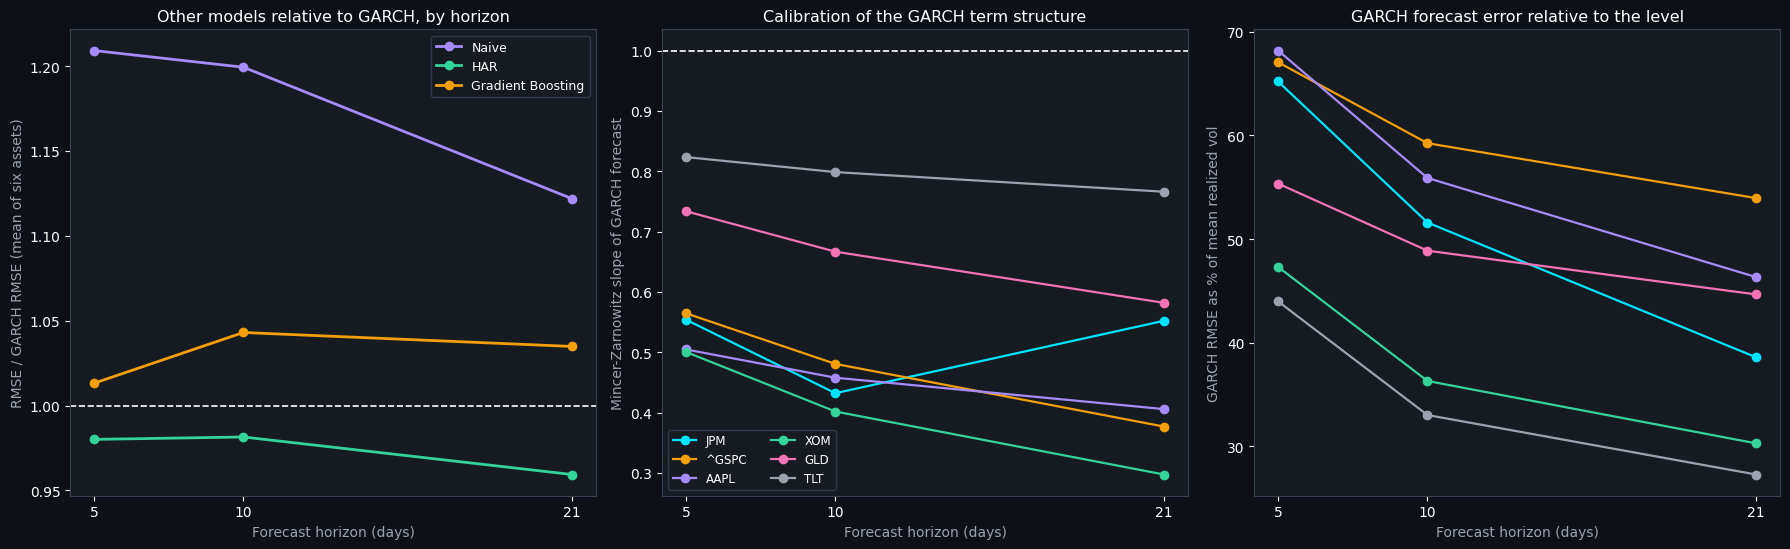

Saved chart_part8_horizons.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
ax = axes[0]
for m, col, lab in (('naive', '#a78bfa', 'Naive'), ('har', '#34d399', 'HAR'), ('gbr', '#f59e0b', 'Gradient Boosting')):
    vals = [summ.loc[h, f'{m}_over_garch'] for h in HORIZONS]
    ax.plot(HORIZONS, vals, marker='o', color=col, lw=2, label=lab)
ax.axhline(1, color='white', ls='--', lw=1.2)
ax.set_xticks(HORIZONS)
ax.set_xlabel('Forecast horizon (days)', color='#9ca3af')
ax.set_ylabel('RMSE / GARCH RMSE (mean of six assets)', color='#9ca3af')
ax.set_title('Other models relative to GARCH, by horizon', color='white', fontsize=11.5)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)
ax = axes[1]
for tk, col in zip(TICKERS, ['#00e5ff', '#f59e0b', '#a78bfa', '#34d399', '#f472b6', '#9ca3af']):
    s = mz[(mz.ticker == tk) & (mz.model == 'garch')].sort_values('horizon')
    ax.plot(s['horizon'], s['slope'], marker='o', color=col, lw=1.6, label=tk)
ax.axhline(1, color='white', ls='--', lw=1.2)
ax.set_xticks(HORIZONS)
ax.set_xlabel('Forecast horizon (days)', color='#9ca3af')
ax.set_ylabel('Mincer-Zarnowitz slope of GARCH forecast', color='#9ca3af')
ax.set_title('Calibration of the GARCH term structure', color='white', fontsize=11.5)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8.5, ncol=2)
ax = axes[2]
for tk, col in zip(TICKERS, ['#00e5ff', '#f59e0b', '#a78bfa', '#34d399', '#f472b6', '#9ca3af']):
    s = byh[byh.ticker == tk].sort_values('horizon')
    ax.plot(s['horizon'], s['garch_rmse_pct_of_mean'], marker='o', color=col, lw=1.6, label=tk)
ax.set_xticks(HORIZONS)
ax.set_xlabel('Forecast horizon (days)', color='#9ca3af')
ax.set_ylabel('GARCH RMSE as % of mean realized vol', color='#9ca3af')
ax.set_title('GARCH forecast error relative to the level', color='white', fontsize=11.5)
plt.tight_layout()
plt.savefig('chart_part8_horizons.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part8_horizons.png')

## 7. Summary and saved tables

In [8]:
fc.to_csv('part8_forecasts.csv')
byh.to_csv('part8_by_horizon.csv', index=False)
mz.to_csv('part8_mincer_zarnowitz.csv', index=False)
pers.to_csv('part8_persistence.csv', index=False)
print('=' * 70)
print('PART 8 SUMMARY: HORIZONS')
print('=' * 70)
print(summ.round(3).to_string())
print()
print('Files saved: chart_part8_horizons.png, part8_forecasts.csv, part8_by_horizon.csv, part8_mincer_zarnowitz.csv, part8_persistence.csv')

PART 8 SUMMARY: HORIZONS
         naive_over_garch  har_over_garch  gbr_over_garch  garch_rmse_pct_of_mean  garch_best_assets
horizon                                                                                             
5                   1.209           0.980           1.013                  57.845                  0
10                  1.199           0.981           1.043                  47.486                  1
21                  1.122           0.959           1.035                  40.179                  1

Files saved: chart_part8_horizons.png, part8_forecasts.csv, part8_by_horizon.csv, part8_mincer_zarnowitz.csv, part8_persistence.csv
